In [28]:
!pip -q install -U huggingface_hub "tokenizers>=0.22.0,<=0.23.0"

In [29]:
import os
import re
import gc
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import NFKC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Change only if your assigned language is different.
LANGUAGE = "hi"

DEV_SIZE = 1000
TEST_SIZE = 1000
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]

WORKDIR = Path("/content/illm_lab3")
WORKDIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", WORKDIR)

Working directory: /content/illm_lab3


In [30]:
def show_disk():
    total, used, free = shutil.disk_usage("/content")
    print(f"Total: {total/1024**3:.2f} GB")
    print(f"Used : {used/1024**3:.2f} GB")
    print(f"Free : {free/1024**3:.2f} GB")

show_disk()

Total: 107.72 GB
Used : 21.00 GB
Free : 86.70 GB


## IndicCorp v2 file selection

The previous version used `load_dataset(...)`, which tried to reconstruct huge files for many languages.

This version uses direct Hub downloads and processes files as streams.

For Hindi, the corpus has `hi-1.txt`, `hi-2.txt`, and `hi-3.txt`. The code starts with `hi-1.txt` and only moves to the next shard if it still needs more sentences.

In [31]:
REPO_ID = "ai4bharat/IndicCorpV2"

LANGUAGE_FILES = {
    "hi": ["data/hi-1.txt", "data/hi-2.txt", "data/hi-3.txt"],
    "gu": ["data/gu.txt"],
    "bn": ["data/bn.txt"],
    "as": ["data/as.txt"],
    "gom": ["data/gom.txt"],
    "bd": ["data/bd.txt"],
    "dg": ["data/dg.txt"],
}

if LANGUAGE not in LANGUAGE_FILES:
    raise ValueError(f"Unsupported language: {LANGUAGE}. Choose from {list(LANGUAGE_FILES)}")

TARGET_SENTENCES = 1_000_000 + DEV_SIZE + TEST_SIZE + 20_000

print("Language:", LANGUAGE)
print("Target sentences:", TARGET_SENTENCES)
print("Shards:", LANGUAGE_FILES[LANGUAGE])

Language: hi
Target sentences: 1022000
Shards: ['data/hi-1.txt', 'data/hi-2.txt', 'data/hi-3.txt']


## Sentence tokenizer
IndicCorp rows are paragraphs, so we first split paragraphs into sentences.

In [32]:
SENTENCE_END = re.compile(r'(?<=[.!?।॥])\s+')

def normalize_text(text):
    text = str(text)
    text = text.replace("\u200c", "").replace("\u200d", "")
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def sentence_tokenize(paragraph):
    paragraph = normalize_text(paragraph)
    if not paragraph:
        return []

    # Protect decimal points such as 3.14.
    paragraph = re.sub(r"(?<=\d)\.(?=\d)", "<DECIMAL_DOT>", paragraph)
    parts = SENTENCE_END.split(paragraph)

    result = []
    for p in parts:
        p = p.replace("<DECIMAL_DOT>", ".").strip()
        if len(p) >= 2:
            result.append(p)
    return result

print(sentence_tokenize("यह पहला वाक्य है। यह दूसरा वाक्य है! यह 3.14 है।"))

['यह पहला वाक्य है।', 'यह दूसरा वाक्य है!', 'यह 3.14 है।']


## Download/process only the required shard

The file is processed line-by-line. We do not load the entire raw file into RAM.

After a shard has been processed, the downloaded shard is deleted to reduce disk usage.

In [33]:
def collect_sentences_from_shard(filename, target_count):
    print(f"\nDownloading/processing: {filename}")

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type="dataset",
        local_dir=str(WORKDIR / "raw"),
        local_dir_use_symlinks=False
    )

    print("Downloaded to:", local_path)

    collected = []

    with open(local_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in tqdm(f, desc=f"Reading {Path(filename).name}"):
            if not line.strip():
                continue

            collected.extend(sentence_tokenize(line))

            if len(collected) >= target_count:
                break

    try:
        os.remove(local_path)
    except OSError:
        pass

    gc.collect()
    show_disk()

    return collected[:target_count]

all_sentences = []

for shard in LANGUAGE_FILES[LANGUAGE]:
    remaining = TARGET_SENTENCES - len(all_sentences)

    if remaining <= 0:
        break

    shard_sentences = collect_sentences_from_shard(shard, remaining)
    all_sentences.extend(shard_sentences)

    print("Collected:", len(all_sentences))

    if len(all_sentences) >= TARGET_SENTENCES:
        break

print("FINAL SENTENCE COUNT:", len(all_sentences))


Downloading/processing: data/hi-1.txt


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


data/hi-1.txt: reconstructing file:   0%|          |  0.00B / 26.7GB            

data/hi-1.txt: downloading bytes:           |  0.00B            

Downloaded to: /content/illm_lab3/raw/data/hi-1.txt


Reading hi-1.txt: 0it [00:00, ?it/s]

Total: 107.72 GB
Used : 21.00 GB
Free : 86.69 GB
Collected: 1022000
FINAL SENTENCE COUNT: 1022000


In [34]:
required = 1_000_000 + DEV_SIZE + TEST_SIZE

if len(all_sentences) < required:
    raise RuntimeError(
        f"Only {len(all_sentences):,} sentences collected; "
        f"{required:,} are required for the complete assignment."
    )

print("Enough sentences collected:", len(all_sentences))

Enough sentences collected: 1022000


## Length-aware train/dev/test split

In [35]:
def length_aware_split(sentences, dev_size=1000, test_size=1000, seed=42, n_bins=20):
    rng = np.random.default_rng(seed)

    lengths = np.array([len(s) for s in sentences])
    edges = np.unique(np.quantile(lengths, np.linspace(0, 1, n_bins + 1)))

    if len(edges) < 3:
        raise RuntimeError("Not enough sentence-length variation.")

    bucket_ids = np.digitize(lengths, edges[1:-1], right=True)

    buckets = {}
    for idx, bucket in enumerate(bucket_ids):
        buckets.setdefault(int(bucket), []).append(idx)

    for bucket in buckets:
        rng.shuffle(buckets[bucket])

    def sample_stratified(n):
        selected = []
        active = sorted(buckets)

        while len(selected) < n and active:
            next_active = []

            for bucket in active:
                if len(selected) >= n:
                    break
                if buckets[bucket]:
                    selected.append(buckets[bucket].pop())
                if buckets[bucket]:
                    next_active.append(bucket)

            active = next_active

        return selected

    dev_idx = sample_stratified(dev_size)
    test_idx = sample_stratified(test_size)

    held_out = set(dev_idx) | set(test_idx)

    train = [s for i, s in enumerate(sentences) if i not in held_out]
    dev = [sentences[i] for i in dev_idx]
    test = [sentences[i] for i in test_idx]

    return train, dev, test

train_sentences, dev_sentences, test_sentences = length_aware_split(
    all_sentences, DEV_SIZE, TEST_SIZE, SEED
)

print("Train:", len(train_sentences))
print("Dev  :", len(dev_sentences))
print("Test :", len(test_sentences))

Train: 1020000
Dev  : 1000
Test : 1000


,split,count,min_chars,mean_chars,median_chars,max_chars
0,train,1000000,2,88.998348,77.0,5163
1,dev,1000,2,89.023000,77.5,589
2,test,1000,3,88.149000,77.5,462


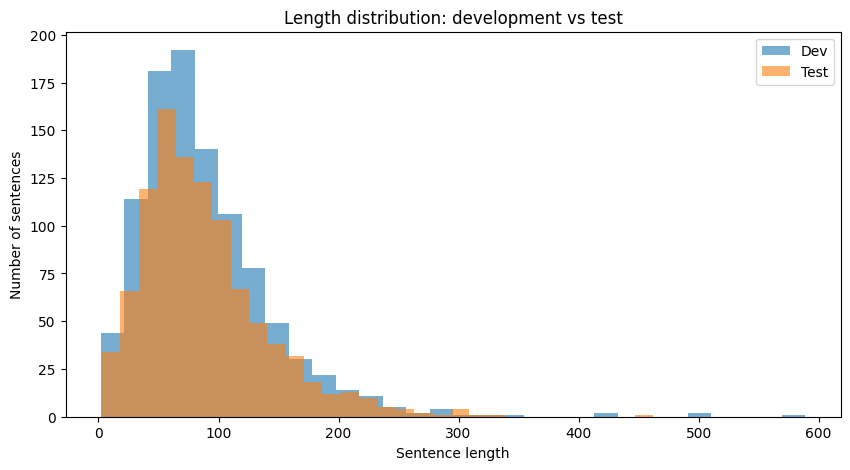

In [36]:
def split_stats(name, data):
    x = np.array([len(s) for s in data])
    return {
        "split": name,
        "count": len(data),
        "min_chars": int(x.min()),
        "mean_chars": float(x.mean()),
        "median_chars": float(np.median(x)),
        "max_chars": int(x.max())
    }

display(pd.DataFrame([
    split_stats("train", train_sentences[:1_000_000]),
    split_stats("dev", dev_sentences),
    split_stats("test", test_sentences)
]))

plt.figure(figsize=(10,5))
plt.hist([len(s) for s in dev_sentences], bins=30, alpha=0.6, label="Dev")
plt.hist([len(s) for s in test_sentences], bins=30, alpha=0.6, label="Test")
plt.xlabel("Sentence length")
plt.ylabel("Number of sentences")
plt.title("Length distribution: development vs test")
plt.legend()
plt.show()

## Save the selected 1M training sentences and dev/test files

In [37]:
def save_sentences(sentences, path):
    with open(path, "w", encoding="utf-8") as f:
        for s in sentences:
            f.write(s.replace("\n", " ").strip() + "\n")

TRAIN_1M = WORKDIR / "train_1m.txt"
DEV_FILE = WORKDIR / "dev.txt"
TEST_FILE = WORKDIR / "test.txt"

save_sentences(train_sentences[:1_000_000], TRAIN_1M)
save_sentences(dev_sentences, DEV_FILE)
save_sentences(test_sentences, TEST_FILE)

print(TRAIN_1M)
print(DEV_FILE)
print(TEST_FILE)

show_disk()

/content/illm_lab3/train_1m.txt
/content/illm_lab3/dev.txt
/content/illm_lab3/test.txt
Total: 107.72 GB
Used : 21.00 GB
Free : 86.69 GB


## BPE — Hugging Face implementation

In [38]:
def train_bpe(train_file, vocab_size):
    tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = Whitespace()

    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]
    )

    tokenizer.train([str(train_file)], trainer)
    return tokenizer

## WordPiece — Hugging Face implementation

In [39]:
def train_wordpiece(train_file, vocab_size):
    tokenizer = Tokenizer(
        WordPiece(
            unk_token="[UNK]",
            continuing_subword_prefix="##"
        )
    )
    tokenizer.normalizer = NFKC()
    tokenizer.pre_tokenizer = Whitespace()

    trainer = WordPieceTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"]
    )

    tokenizer.train([str(train_file)], trainer)
    return tokenizer

## Quick test before large experiments

In [40]:
TEST_TRAIN = WORKDIR / "train_100k.txt"
save_sentences(train_sentences[:100_000], TEST_TRAIN)

bpe_test = train_bpe(TEST_TRAIN, 20_000)
wp_test = train_wordpiece(TEST_TRAIN, 20_000)

sample = dev_sentences[0]

print("Original:")
print(sample)
print("\nBPE:")
print(bpe_test.encode(sample).tokens)
print("\nWordPiece:")
print(wp_test.encode(sample).tokens)

Original:
2.

BPE:
['2', '.']

WordPiece:
['2', '.']


## Evaluation helper

In [41]:
def evaluate_tokenizer(tokenizer, data):
    token_counts = []
    unk = 0
    total = 0

    for sentence in tqdm(data, desc="Tokenizing", leave=False):
        tokens = tokenizer.encode(sentence).tokens
        token_counts.append(len(tokens))
        total += len(tokens)
        unk += sum(t == "[UNK]" for t in tokens)

    chars = sum(len(s.replace(" ", "")) for s in data)

    return {
        "avg_tokens_per_sentence": float(np.mean(token_counts)),
        "median_tokens_per_sentence": float(np.median(token_counts)),
        "unk_rate": float(unk / max(total, 1)),
        "chars_per_token": float(chars / max(total, 1)),
        "total_tokens": int(total)
    }

# Experiment A — Training data size

Vocabulary size is fixed at 30,000.

Required:
- 100K
- 300K
- 500K
- 1M

In [42]:
size_results = []
size_models = {}

for n in TRAIN_SIZES:
    print("\n" + "="*70)
    print(f"Training size: {n:,}")
    print("="*70)

    train_file = WORKDIR / f"train_{n}.txt"
    save_sentences(train_sentences[:n], train_file)

    bpe = train_bpe(train_file, 30_000)
    wp = train_wordpiece(train_file, 30_000)

    size_models[(n, "BPE")] = bpe
    size_models[(n, "WordPiece")] = wp

    for name, tok in [("BPE", bpe), ("WordPiece", wp)]:
        d = evaluate_tokenizer(tok, dev_sentences)
        t = evaluate_tokenizer(tok, test_sentences)

        size_results.append({
            "training_size": n,
            "tokenizer": name,
            "dev_avg_tokens": d["avg_tokens_per_sentence"],
            "test_avg_tokens": t["avg_tokens_per_sentence"],
            "dev_unk_rate": d["unk_rate"],
            "test_unk_rate": t["unk_rate"],
            "dev_chars_per_token": d["chars_per_token"],
            "test_chars_per_token": t["chars_per_token"]
        })

size_df = pd.DataFrame(size_results)
display(size_df)


Training size: 100,000


Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

...

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

,training_size,tokenizer,dev_avg_tokens,test_avg_tokens,dev_unk_rate,test_unk_rate,dev_chars_per_token,test_chars_per_token
0,100000,BPE,20.619,20.441,0.0,0.000049,3.512537,3.508732
1,100000,WordPiece,20.773,20.680,0.0,0.000048,3.486497,3.468182
2,300000,BPE,20.549,20.394,0.0,0.000049,3.524502,3.516819
3,300000,WordPiece,20.700,20.626,0.0,0.000048,3.498792,3.477262
4,500000,BPE,20.532,20.372,0.0,0.000049,3.527421,3.520617
5,500000,WordPiece,20.722,20.619,0.0,0.000048,3.495078,3.478442
6,1000000,BPE,20.533,20.366,0.0,0.000000,3.527249,3.521654
7,1000000,WordPiece,20.735,20.614,0.0,0.000000,3.492886,3.479286


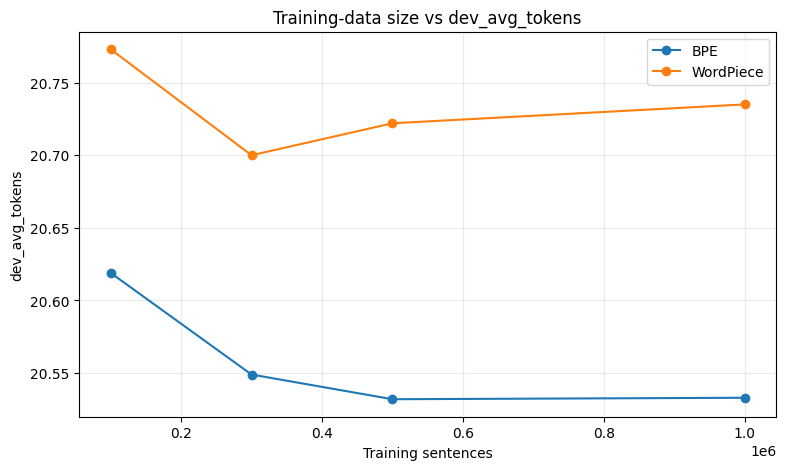

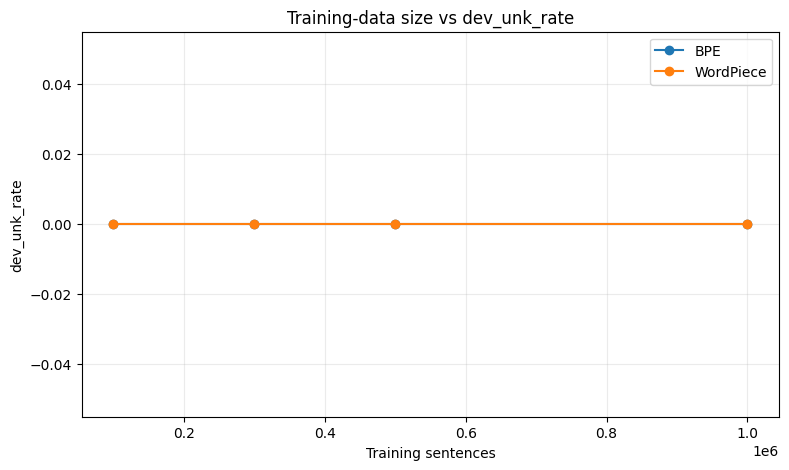

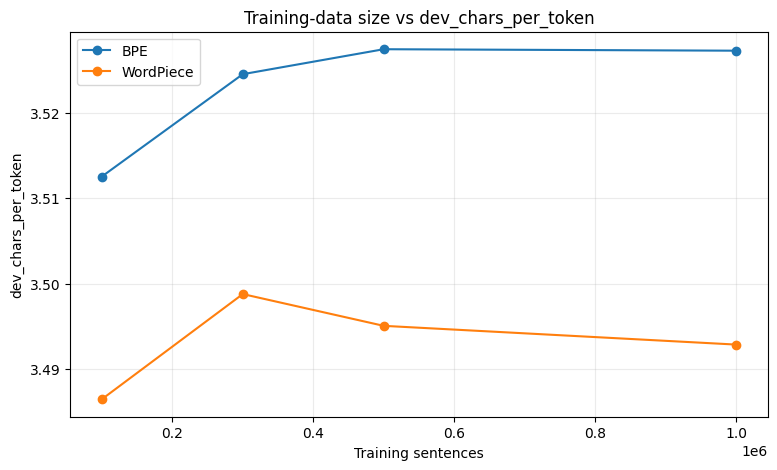

In [43]:
for metric in ["dev_avg_tokens", "dev_unk_rate", "dev_chars_per_token"]:
    plt.figure(figsize=(9,5))
    for name in ["BPE", "WordPiece"]:
        sub = size_df[size_df.tokenizer == name]
        plt.plot(sub.training_size, sub[metric], marker="o", label=name)
    plt.xlabel("Training sentences")
    plt.ylabel(metric)
    plt.title(f"Training-data size vs {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

# Experiment B — Vocabulary size

Training data is fixed to 1,000,000 sentences.

Required:
- 20K
- 30K
- 50K

In [44]:
vocab_results = []
vocab_models = {}

for vocab_size in VOCAB_SIZES:
    print("\n" + "="*70)
    print(f"Vocabulary size: {vocab_size:,}")
    print("="*70)

    bpe = train_bpe(TRAIN_1M, vocab_size)
    wp = train_wordpiece(TRAIN_1M, vocab_size)

    vocab_models[(vocab_size, "BPE")] = bpe
    vocab_models[(vocab_size, "WordPiece")] = wp

    for name, tok in [("BPE", bpe), ("WordPiece", wp)]:
        d = evaluate_tokenizer(tok, dev_sentences)
        t = evaluate_tokenizer(tok, test_sentences)

        vocab_results.append({
            "vocab_size": vocab_size,
            "tokenizer": name,
            "dev_avg_tokens": d["avg_tokens_per_sentence"],
            "test_avg_tokens": t["avg_tokens_per_sentence"],
            "dev_unk_rate": d["unk_rate"],
            "test_unk_rate": t["unk_rate"],
            "dev_chars_per_token": d["chars_per_token"],
            "test_chars_per_token": t["chars_per_token"]
        })

vocab_df = pd.DataFrame(vocab_results)
display(vocab_df)


Vocabulary size: 20,000


Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

...

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing:   0%|          | 0/1000 [00:00<?, ?it/s]

,vocab_size,tokenizer,dev_avg_tokens,test_avg_tokens,dev_unk_rate,test_unk_rate,dev_chars_per_token,test_chars_per_token
0,20000,BPE,21.065,20.857,0.0,0.0,3.438168,3.438750
1,20000,WordPiece,21.393,21.240,0.0,0.0,3.385453,3.376742
2,30000,BPE,20.533,20.366,0.0,0.0,3.527249,3.521654
3,30000,WordPiece,20.735,20.614,0.0,0.0,3.492886,3.479286
4,50000,BPE,20.107,19.972,0.0,0.0,3.601979,3.591128
5,50000,WordPiece,20.240,20.120,0.0,0.0,3.578310,3.564712


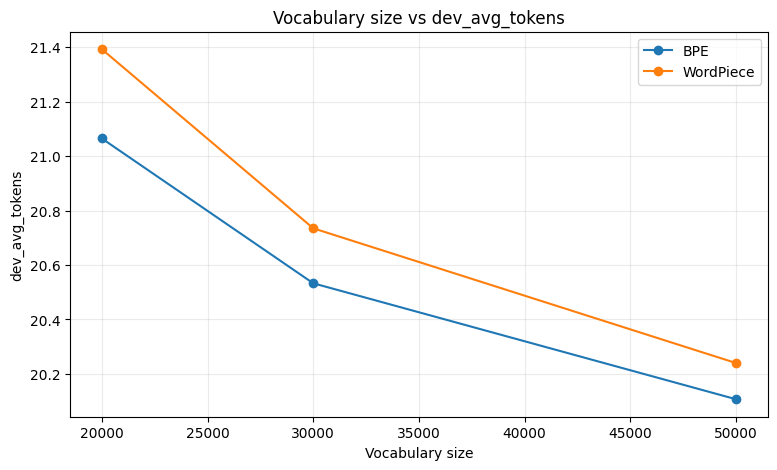

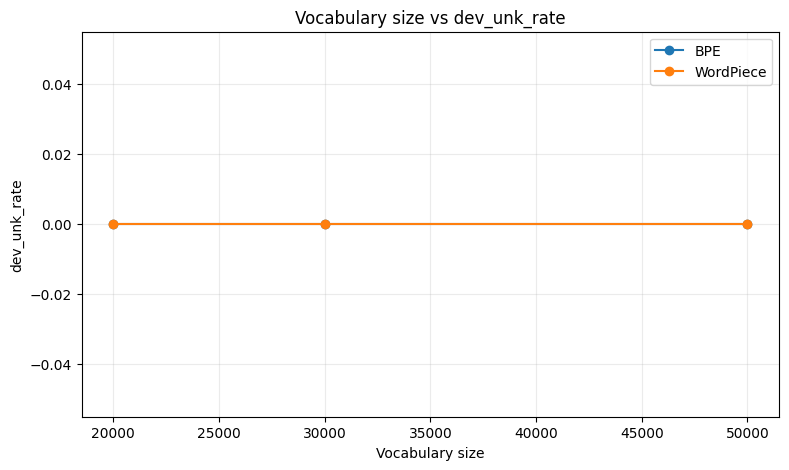

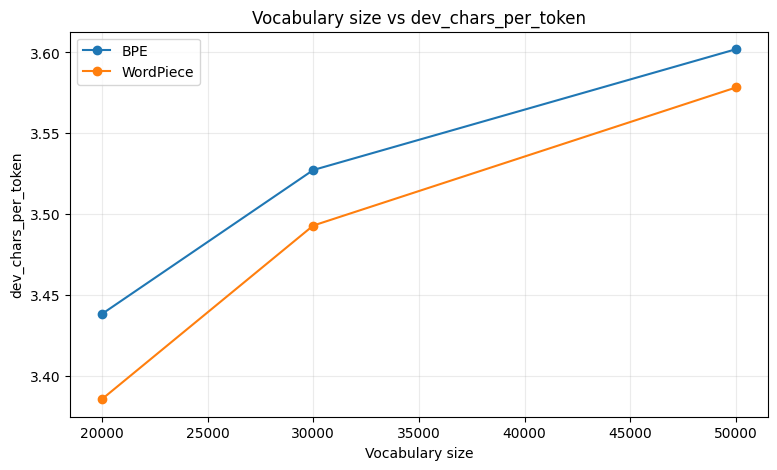

In [45]:
for metric in ["dev_avg_tokens", "dev_unk_rate", "dev_chars_per_token"]:
    plt.figure(figsize=(9,5))
    for name in ["BPE", "WordPiece"]:
        sub = vocab_df[vocab_df.tokenizer == name]
        plt.plot(sub.vocab_size, sub[metric], marker="o", label=name)
    plt.xlabel("Vocabulary size")
    plt.ylabel(metric)
    plt.title(f"Vocabulary size vs {metric}")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

## Qualitative tokenization comparison

In [46]:
for i, sentence in enumerate(dev_sentences[:5], 1):
    print("\n" + "="*90)
    print(f"Example {i}: {sentence}")

    for vocab_size in VOCAB_SIZES:
        for name in ["BPE", "WordPiece"]:
            tok = vocab_models[(vocab_size, name)]
            print(f"{name} {vocab_size//1000}K:")
            print(tok.encode(sentence).tokens)


Example 1: 2.
BPE 20K:
['2', '.']
WordPiece 20K:
['2', '.']
BPE 30K:
['2', '.']
WordPiece 30K:
['2', '.']
BPE 50K:
['2', '.']
WordPiece 50K:
['2', '.']

Example 2: आर्थिक लाभ की संभावनाएँ हैं।
BPE 20K:
['आर्थिक', 'लाभ', 'की', 'संभावना', 'एँ', 'हैं', '।']
WordPiece 20K:
['आर्थिक', 'लाभ', 'की', 'संभावना', '##एँ', 'हैं', '।']
BPE 30K:
['आर्थिक', 'लाभ', 'की', 'संभावना', 'एँ', 'हैं', '।']
WordPiece 30K:
['आर्थिक', 'लाभ', 'की', 'संभावना', '##एँ', 'हैं', '।']
BPE 50K:
['आर्थिक', 'लाभ', 'की', 'संभावना', 'एँ', 'हैं', '।']
WordPiece 50K:
['आर्थिक', 'लाभ', 'की', 'संभावना', '##एँ', 'हैं', '।']

Example 3: यह फिल्म साल 2009 में रिलीज हुई थी।
BPE 20K:
['यह', 'फिल्म', 'साल', '2009', 'में', 'रिलीज', 'हुई', 'थी', '।']
WordPiece 20K:
['यह', 'फिल्म', 'साल', '2009', 'में', 'रिलीज', 'हुई', 'थी', '।']
BPE 30K:
['यह', 'फिल्म', 'साल', '2009', 'में', 'रिलीज', 'हुई', 'थी', '।']
WordPiece 30K:
['यह', 'फिल्म', 'साल', '2009', 'में', 'रिलीज', 'हुई', 'थी', '।']
BPE 50K:
['यह', 'फिल्म', 'साल', '2009', 'में', 'रिलीज'

## Final comparison tables

In [47]:
print("TRAINING SIZE EXPERIMENT")
display(size_df)

print("\nVOCABULARY SIZE EXPERIMENT")
display(vocab_df)

TRAINING SIZE EXPERIMENT


,training_size,tokenizer,dev_avg_tokens,test_avg_tokens,dev_unk_rate,test_unk_rate,dev_chars_per_token,test_chars_per_token
0,100000,BPE,20.619,20.441,0.0,0.000049,3.512537,3.508732
1,100000,WordPiece,20.773,20.680,0.0,0.000048,3.486497,3.468182
2,300000,BPE,20.549,20.394,0.0,0.000049,3.524502,3.516819
3,300000,WordPiece,20.700,20.626,0.0,0.000048,3.498792,3.477262
4,500000,BPE,20.532,20.372,0.0,0.000049,3.527421,3.520617
5,500000,WordPiece,20.722,20.619,0.0,0.000048,3.495078,3.478442
6,1000000,BPE,20.533,20.366,0.0,0.000000,3.527249,3.521654
7,1000000,WordPiece,20.735,20.614,0.0,0.000000,3.492886,3.479286



VOCABULARY SIZE EXPERIMENT


,vocab_size,tokenizer,dev_avg_tokens,test_avg_tokens,dev_unk_rate,test_unk_rate,dev_chars_per_token,test_chars_per_token
0,20000,BPE,21.065,20.857,0.0,0.0,3.438168,3.438750
1,20000,WordPiece,21.393,21.240,0.0,0.0,3.385453,3.376742
2,30000,BPE,20.533,20.366,0.0,0.0,3.527249,3.521654
3,30000,WordPiece,20.735,20.614,0.0,0.0,3.492886,3.479286
4,50000,BPE,20.107,19.972,0.0,0.0,3.601979,3.591128
5,50000,WordPiece,20.240,20.120,0.0,0.0,3.578310,3.564712


In [48]:
size_df.to_csv(WORKDIR / "training_size_results.csv", index=False)
vocab_df.to_csv(WORKDIR / "vocabulary_size_results.csv", index=False)

pd.DataFrame([
    {"split": "train", "sentences": 1_000_000},
    {"split": "dev", "sentences": len(dev_sentences)},
    {"split": "test", "sentences": len(test_sentences)}
]).to_csv(WORKDIR / "split_sizes.csv", index=False)

for (n, name), tok in size_models.items():
    tok.save(str(WORKDIR / f"{name.lower()}_train_{n}_30k.json"))

for (v, name), tok in vocab_models.items():
    tok.save(str(WORKDIR / f"{name.lower()}_vocab_{v}.json"))

print("Saved results and tokenizer JSON files in:", WORKDIR)
for p in sorted(WORKDIR.glob("*")):
    print(p.name)

Saved results and tokenizer JSON files in: /content/illm_lab3
bpe_train_1000000_30k.json
bpe_train_100000_30k.json
bpe_train_300000_30k.json
bpe_train_500000_30k.json
bpe_vocab_20000.json
bpe_vocab_30000.json
bpe_vocab_50000.json
dev.txt
raw
split_sizes.csv
test.txt
train_100000.txt
train_1000000.txt
train_100k.txt
train_1m.txt
train_300000.txt
train_500000.txt
training_size_results.csv
vocabulary_size_results.csv
wordpiece_train_1000000_30k.json
wordpiece_train_100000_30k.json
wordpiece_train_300000_30k.json
wordpiece_train_500000_30k.json
wordpiece_vocab_20000.json
wordpiece_vocab_30000.json
wordpiece_vocab_50000.json


# Assignment checklist

- Sentence tokenization of paragraph rows
- Length-aware dev/test selection
- 1000 development sentences
- 1000 test sentences
- BPE using Hugging Face `tokenizers`
- WordPiece using Hugging Face `tokenizers`
- 100K / 300K / 500K / 1M training sizes
- 20K / 30K / 50K vocabulary sizes
- Dev/test tokenization
- Quantitative comparison
- Graphs
- Qualitative comparison
- Saved CSV results

### Disk-space fix

This notebook does **not** use:

```python
load_dataset("ai4bharat/IndicCorpV2", split="train")
```

Instead it downloads one language shard at a time, reads it line-by-line, stops once enough sentences are collected, and removes the raw shard afterwards.